In [1]:
from pathlib import Path
import sqlite3
import pandas as pd

# Look for the database from either the project folder or notebooks/ folder.
db_path = Path("data/jobs.db")
if not db_path.exists():
    db_path = Path("../data/jobs.db")

# Connect to SQLite, load the postings into pandas, then close the connection.
connection = sqlite3.connect(db_path)
df = pd.read_sql_query("SELECT * FROM job_postings_clean", connection)
connection.close()

print(f"Loaded {df.shape[0]} rows and {df.shape[1]} columns.")

Loaded 29425 rows and 14 columns.


In [2]:
df.head()

,Uniq Id,Crawl Timestamp,Job Title,Job Salary,Job Experience Required,Key Skills,Role Category,Location,Functional Area,Industry,Role,salary_min_lpa,salary_max_lpa,salary_mid_lpa
0,9be62c49a0b7ebe982a4af1edaa7bc5f,2019-07-05 01:46:07 +0000,Digital Media Planner,Not Disclosed by Recruiter,5 - 10 yrs,Media Planning| Digital Media,Advertising,Mumbai,"Marketing , Advertising , MR , PR , Media Plan...","Advertising, PR, MR, Event Management",Media Planning Executive/Manager,NaN,NaN,NaN
1,3c52d436e39f596b22519da2612f6a56,2019-07-06 08:04:50 +0000,Online Bidding Executive,Not Disclosed by Recruiter,2 - 5 yrs,pre sales| closing| software knowledge| client...,Retail Sales,Pune,"Sales , Retail , Business Development","IT-Software, Software Services",Sales Executive/Officer,NaN,NaN,NaN
2,ffad8a2396c60be2bf6d0e2ff47c58d4,2019-08-05 15:50:44 +0000,Trainee Research/ Research Executive- Hi- Tech...,Not Disclosed by Recruiter,0 - 1 yrs,Computer science| Fabrication| Quality check| ...,R&D,Gurgaon,"Engineering Design , R&D","Recruitment, Staffing",R&D Executive,NaN,NaN,NaN
3,7b921f51b5c2fb862b4a5f7a54c37f75,2019-08-05 15:31:56 +0000,Technical Support,"2,00,000 - 4,00,000 PA.",0 - 5 yrs,Technical Support,Admin/Maintenance/Security/Datawarehousing,Mumbai,"IT Software - Application Programming , Mainte...","IT-Software, Software Services",Technical Support Engineer,2.0,4.0,3.0
4,2d8b7d44e138a54d5dc841163138de50,2019-07-05 02:48:29 +0000,Software Test Engineer -hyderabad,Not Disclosed by Recruiter,2 - 5 yrs,manual testing| test engineering| test cases| ...,Programming & Design,Hyderabad,IT Software - QA & Testing,"IT-Software, Software Services",Testing Engineer,NaN,NaN,NaN


In [3]:
df["Role"].value_counts().head(10)


Role
Software Developer                            6396
Associate/Senior Associate -(NonTechnical)    1725
Sales/Business Development Manager            1561
Sales Executive/Officer                       1168
Other                                          896
Team Lead/Technical Lead                       847
Associate/Senior Associate -(Technical)        513
Accounts Executive/Accountant                  511
Recruitment Executive                          427
Testing Engineer                               408
Name: count, dtype: int64

In [4]:
df["Key Skills"].dropna().head(10)


0                        Media Planning| Digital Media
1    pre sales| closing| software knowledge| client...
2    Computer science| Fabrication| Quality check| ...
3                                    Technical Support
4    manual testing| test engineering| test cases| ...
5    adobe experience manager| digital| digital mar...
6    channel partners| real estate| negotiation| pr...
7    TFS| Azure| Git| VSTS| Docker| DynaTrace| Splu...
8                                                  Bde
9    technical support| support services| applicati...
Name: Key Skills, dtype: str

In [5]:
skill_rows = df[["Uniq Id", "Key Skills"]].dropna(subset=["Key Skills"])

skill_rows["skill"] = skill_rows["Key Skills"].str.split("|", regex=False)
skill_rows = skill_rows.explode("skill")
skill_rows["skill"] = skill_rows["skill"].str.strip().str.lower()

skill_rows = skill_rows[skill_rows["skill"] != ""]
skill_rows.head(20)

,Uniq Id,Key Skills,skill
0,9be62c49a0b7ebe982a4af1edaa7bc5f,Media Planning| Digital Media,media planning
0,9be62c49a0b7ebe982a4af1edaa7bc5f,Media Planning| Digital Media,digital media
1,3c52d436e39f596b22519da2612f6a56,pre sales| closing| software knowledge| client...,pre sales
1,3c52d436e39f596b22519da2612f6a56,pre sales| closing| software knowledge| client...,closing
1,3c52d436e39f596b22519da2612f6a56,pre sales| closing| software knowledge| client...,software knowledge
1,3c52d436e39f596b22519da2612f6a56,pre sales| closing| software knowledge| client...,clients
1,3c52d436e39f596b22519da2612f6a56,pre sales| closing| software knowledge| client...,requirements
1,3c52d436e39f596b22519da2612f6a56,pre sales| closing| software knowledge| client...,negotiating
1,3c52d436e39f596b22519da2612f6a56,pre sales| closing| software knowledge| client...,client
1,3c52d436e39f596b22519da2612f6a56,pre sales| closing| software knowledge| client...,online bidding


In [6]:
skill_rows["skill"].value_counts().head(20)

skill
javascript              2264
sales                   1868
sql                     1562
html                    1540
customer service        1340
java                    1234
python                  1177
jquery                  1091
business development    1079
recruitment             1064
technical support       1030
management               953
mysql                    925
bpo                      876
c                        821
project management       816
business executive       813
web technologies         801
linux                    792
marketing                764
Name: count, dtype: int64

In [7]:
unique_skill_rows = skill_rows.drop_duplicates(subset=["Uniq Id", "skill"])
unique_skill_rows["skill"].value_counts().head(20)

skill
javascript              2254
sales                   1863
sql                     1560
html                    1539
customer service        1289
java                    1233
python                  1177
jquery                  1085
business development    1078
recruitment             1063
technical support       1030
management               949
mysql                    924
bpo                      876
c                        819
project management       816
business executive       813
web technologies         801
linux                    792
marketing                763
Name: count, dtype: int64

In [8]:
df["Location"].value_counts().head(10)

Location
Bengaluru    5240
Mumbai       3463
Pune         2529
Hyderabad    2300
Gurgaon      1826
Chennai      1651
Kolkata      1377
Delhi        1257
Noida        1181
Ahmedabad    1055
Name: count, dtype: int64

In [9]:
connection = sqlite3.connect(db_path)

top_skills = pd.read_sql_query(
    """
    SELECT skill, COUNT(DISTINCT job_id) AS posting_count
    FROM job_skills
    GROUP BY skill
    ORDER BY posting_count DESC
    LIMIT 20
    """,
    connection,
)

connection.close()
top_skills


,skill,posting_count
0,javascript,2254
1,sales,1863
2,sql,1560
3,html,1539
4,customer service,1289
5,java,1233
6,python,1177
7,jquery,1085
8,business development,1078
9,recruitment,1063


## Initial findings

This analysis uses 29,425 cleaned postings from a 30,000-row Naukri.com dataset. It is a historical 2019 sample, not a feed of current job openings.

- 575 postings without a job title were removed; no duplicate job IDs were found.
- Software Developer was the most common role, with 6,396 postings (about 21.7%).
- Bengaluru was the most common location, with 5,215 postings (about 17.7%).
- Bengaluru, Mumbai, and Pune together had 11,119 postings (about 37.8%).
- JavaScript appeared in 2,254 postings, SQL in 1,560, and Python in 1,177.

Skill counts come from the dataset's Key Skills field. It includes business and role-related tags as well as technical skills. The dataset has no full job descriptions or company names.

from pathlib import Path
import sys
from sentence_transformers import SentenceTransformer

# Make the project folder visible so this notebook can import code from src/.
project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

# Load the function that builds documents from the cleaned SQLite table.
from src.build_documents import load_job_documents

jobs = load_job_documents(str(project_root / "data" / "jobs.db"))

# Load a pretrained text-to-vector model.
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Encode three documents as vectors and show the vector dimensions.
sample_texts = jobs["document"].head(3).tolist()
vectors = model.encode_document(sample_texts, show_progress_bar=True)

print("Vector shape:", vectors.shape)

In [10]:
from pathlib import Path
import sys
from sentence_transformers import SentenceTransformer

# Make the project folder visible so this notebook can import code from src/.
project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

# Load the function that builds documents from the cleaned SQLite table.
from src.build_documents import load_job_documents

jobs = load_job_documents(str(project_root / "data" / "jobs.db"))

# Load a pretrained text-to-vector model.
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Encode three documents as vectors and show the vector dimensions.
sample_texts = jobs["document"].head(3).tolist()
vectors = model.encode_document(sample_texts, show_progress_bar=True)

print("Vector shape:", vectors.shape)

c:\Users\Ramesh\OneDrive\Pictures\Desktop\Documents\india-job-market-rag-assistant\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 1/1 [00:00<00:00,  7.63it/s]

Vector shape: (3, 384)


In [11]:
from src.salary_parser import parse_salary_lpa

print(parse_salary_lpa("6-10 LPA"))
print(parse_salary_lpa("INR 3,00,000 - 7,00,000 PA"))
print(parse_salary_lpa("Not Disclosed by Recruiter"))

(6.0, 10.0, 8.0)
(3.0, 7.0, 5.0)
None


In [12]:
from pathlib import Path
import sqlite3
import pandas as pd

# Start from the notebook's current folder
project_root = Path.cwd()

# If the notebook runs from the notebooks folder, go up one level
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

database_path = project_root / "data" / "jobs.db"
print("Database path:", database_path)
print("Database exists:", database_path.exists())

# Connect using the full path
connection = sqlite3.connect(database_path)

locations = pd.read_sql_query(
    '''
    SELECT "Location", COUNT(*) AS posting_count
    FROM job_postings_clean
    GROUP BY "Location"
    ORDER BY posting_count DESC
    LIMIT 30
    ''',
    connection,
)

connection.close()
display(locations)

Database path: c:\Users\Ramesh\OneDrive\Pictures\Desktop\Documents\india-job-market-rag-assistant\data\jobs.db
Database exists: True


,Location,posting_count
0,Bengaluru,5240
1,Mumbai,3463
2,Pune,2529
3,Hyderabad,2300
4,Gurgaon,1826
5,Chennai,1651
6,Kolkata,1377
7,Delhi,1257
8,Noida,1181
9,Ahmedabad,1055


In [13]:
from pathlib import Path
import sqlite3
import pandas as pd

project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

connection = sqlite3.connect(project_root / "data" / "jobs.db")

summary = pd.read_sql_query(
    '''
    SELECT
        COUNT(*) AS total_rows,
        SUM(CASE WHEN salary_mid_lpa IS NOT NULL THEN 1 ELSE 0 END)
            AS salaries_parsed,
        SUM(CASE WHEN "Job Title" IS NULL OR TRIM("Job Title") = '' THEN 1 ELSE 0 END)
            AS blank_titles,
        COUNT(DISTINCT "Uniq Id") AS distinct_ids
    FROM job_postings_clean
    ''',
    connection,
)

connection.close()
display(summary)

,total_rows,salaries_parsed,blank_titles,distinct_ids
0,29425,8431,0,29425


In [14]:
from pathlib import Path
import sqlite3
import pandas as pd

project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

connection = sqlite3.connect(project_root / "data" / "jobs.db")

top_skills = pd.read_sql_query(
    '''
    SELECT skill, COUNT(DISTINCT job_id) AS posting_count
    FROM job_skills_normalized
    GROUP BY skill
    ORDER BY posting_count DESC
    LIMIT 20
    ''',
    connection,
)

connection.close()
display(top_skills)

,skill,posting_count
0,javascript,2258
1,sales,1863
2,sql,1560
3,html,1539
4,customer service,1289
5,java,1233
6,python,1177
7,jquery,1085
8,business development,1078
9,recruitment,1063


In [15]:
from pathlib import Path
import sqlite3
import pandas as pd

project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

connection = sqlite3.connect(project_root / "data" / "jobs.db")

technical_skill_counts = pd.read_sql_query(
    '''
    SELECT skill, COUNT(DISTINCT job_id) AS posting_count
    FROM job_technical_skills
    GROUP BY skill
    ORDER BY posting_count DESC
    ''',
    connection,
)

connection.close()
display(technical_skill_counts)

,skill,posting_count
0,javascript,2260
1,sql,2248
2,java,1628
3,html,1554
4,python,1183
5,mysql,955
6,linux,885
7,css,725
8,excel,598
9,data analysis,508


In [16]:
from pathlib import Path
import sqlite3
import pandas as pd

from src.skill_dictionary import extract_skills
from src.technical_skill_matcher import extract_technical_skills

project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

connection = sqlite3.connect(project_root / "data" / "jobs.db")

jobs = pd.read_sql_query(
    'SELECT "Key Skills" FROM job_postings_clean',
    connection,
)

connection.close()


def contains_skill(value, skill, extractor):
    if pd.isna(value):
        return False
    return skill in extractor(value)


for skill in ["sql", "python", "javascript", "java", "html"]:
    dictionary_count = jobs["Key Skills"].apply(
        lambda value: contains_skill(value, skill, extract_skills)
    ).sum()

    spacy_count = jobs["Key Skills"].apply(
        lambda value: contains_skill(value, skill, extract_technical_skills)
    ).sum()

    print(
        f"{skill}: dictionary={dictionary_count}, "
        f"spaCy matcher={spacy_count}"
    )

sql: dictionary=1560, spaCy matcher=2248
python: dictionary=1177, spaCy matcher=1183
javascript: dictionary=2258, spaCy matcher=2260
java: dictionary=1233, spaCy matcher=1628
html: dictionary=1539, spaCy matcher=1554


In [17]:
import importlib
import src.technical_skill_matcher as technical_skill_matcher

# Reload the edited matcher code in the notebook
importlib.reload(technical_skill_matcher)

for skill in ["sql", "python", "javascript", "java", "html"]:
    dictionary_count = jobs["Key Skills"].apply(
        lambda value: contains_skill(value, skill, extract_skills)
    ).sum()

    spacy_count = jobs["Key Skills"].apply(
        lambda value: contains_skill(
            value,
            skill,
            technical_skill_matcher.extract_technical_skills,
        )
    ).sum()

    print(f"{skill}: dictionary={dictionary_count}, spaCy matcher={spacy_count}")

sql: dictionary=1560, spaCy matcher=2248
python: dictionary=1177, spaCy matcher=1183
javascript: dictionary=2258, spaCy matcher=2260
java: dictionary=1233, spaCy matcher=1628
html: dictionary=1539, spaCy matcher=1554


In [18]:
import importlib
import src.technical_skill_matcher as technical_skill_matcher

importlib.reload(technical_skill_matcher)

for skill in ["sql", "python", "javascript", "java", "html"]:
    dictionary_count = jobs["Key Skills"].apply(
        lambda value: contains_skill(value, skill, extract_skills)
    ).sum()

    spacy_count = jobs["Key Skills"].apply(
        lambda value: contains_skill(
            value,
            skill,
            technical_skill_matcher.extract_technical_skills,
        )
    ).sum()

    print(f"{skill}: dictionary={dictionary_count}, spaCy matcher={spacy_count}")

sql: dictionary=1560, spaCy matcher=2248
python: dictionary=1177, spaCy matcher=1183
javascript: dictionary=2258, spaCy matcher=2260
java: dictionary=1233, spaCy matcher=1628
html: dictionary=1539, spaCy matcher=1554


In [19]:
import sqlite3
import pandas as pd
from pathlib import Path

project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

connection = sqlite3.connect(project_root / "data" / "jobs.db")

extra_matches = pd.read_sql_query(
    '''
    SELECT DISTINCT
        technical.skill,
        jobs."Key Skills" AS original_skills
    FROM job_technical_skills AS technical
    JOIN job_postings_clean AS jobs
        ON CAST(jobs."Uniq Id" AS TEXT) = technical.job_id
    LEFT JOIN job_skills_normalized AS normalized
        ON normalized.job_id = technical.job_id
        AND normalized.skill = technical.skill
    WHERE technical.skill IN (
        'sql', 'python', 'javascript', 'java', 'html'
    )
    AND normalized.job_id IS NULL
    LIMIT 30
    ''',
    connection,
)

connection.close()
display(extra_matches)

,skill,original_skills
0,java,Java EE| JMS| Core Java| JUnit| Weblogic| HTML...
1,java,JMS| Core Java| Sonar| Weblogic| XML| J2Ee| SV...
2,sql,analytical| documentation| web development| al...
3,sql,C#|Application Development|Senior Level|MS SQL...
4,java,Oracle|Core Java|Business process|Outsourcing|...
5,java,Java EE| Hibernate| Core Java| Software Develo...
6,sql,SSRS| SQL Server| Stored Procedures| SQL Devel...
7,java,Angularjs| CSS| Core Java| DOM| Computer Scien...
8,java,hive| apache| itil process| hadoop| big data| ...
9,java,J2Ee| Core Java| jQuery| ERP| Tomcat| Eclipse|...


In [20]:
import importlib
import src.technical_skill_matcher as technical_skill_matcher

importlib.reload(technical_skill_matcher)


<module 'src.technical_skill_matcher' from 'c:\\Users\\Ramesh\\OneDrive\\Pictures\\Desktop\\Documents\\india-job-market-rag-assistant\\src\\technical_skill_matcher.py'>

In [21]:
from pathlib import Path
import sqlite3
import pandas as pd

# Locate the project root, including when the notebook runs from notebooks/
project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

connection = sqlite3.connect(project_root / "data" / "jobs.db")

# Select the eight roles with the most postings
top_roles = pd.read_sql_query(
    '''
    SELECT
        COALESCE(NULLIF(TRIM("Role"), ''), 'Unknown') AS role,
        COUNT(*) AS posting_count
    FROM job_postings_clean
    GROUP BY role
    ORDER BY posting_count DESC
    LIMIT 8
    ''',
    connection,
)

# Count postings for each recognized technical skill within each role
role_skills = pd.read_sql_query(
    '''
    SELECT
        COALESCE(NULLIF(TRIM(jobs."Role"), ''), 'Unknown') AS role,
        skills.skill,
        COUNT(DISTINCT skills.job_id) AS posting_count
    FROM job_technical_skills AS skills
    JOIN job_postings_clean AS jobs
        ON CAST(jobs."Uniq Id" AS TEXT) = skills.job_id
    GROUP BY role, skills.skill
    ORDER BY role, posting_count DESC
    ''',
    connection,
)

connection.close()

# Display the five most common recognized technical skills for each top role
for role in top_roles["role"]:
    print(f"\nTop technical skills for: {role}")
    display(
        role_skills[role_skills["role"] == role]
        .head(5)
        .reset_index(drop=True)
    )


Top technical skills for: Software Developer


,role,skill,posting_count
0,Software Developer,javascript,1722
1,Software Developer,sql,1433
2,Software Developer,java,1140
3,Software Developer,html,1065
4,Software Developer,mysql,740



Top technical skills for: Associate/Senior Associate -(NonTechnical)


,role,skill,posting_count
0,Associate/Senior Associate -(NonTechnical),data analysis,66
1,Associate/Senior Associate -(NonTechnical),excel,55
2,Associate/Senior Associate -(NonTechnical),sql,17
3,Associate/Senior Associate -(NonTechnical),html,7
4,Associate/Senior Associate -(NonTechnical),python,6



Top technical skills for: Sales/Business Development Manager


,role,skill,posting_count
0,Sales/Business Development Manager,excel,10
1,Sales/Business Development Manager,data analysis,10
2,Sales/Business Development Manager,git,5
3,Sales/Business Development Manager,java,4
4,Sales/Business Development Manager,sql,3


... (6 outputs left out)


Top technical skills for: Associate/Senior Associate -(Technical)


,role,skill,posting_count
0,Associate/Senior Associate -(Technical),data analysis,29
1,Associate/Senior Associate -(Technical),sql,16
2,Associate/Senior Associate -(Technical),excel,6
3,Associate/Senior Associate -(Technical),python,5
4,Associate/Senior Associate -(Technical),html,5



Top technical skills for: Accounts Executive/Accountant


,role,skill,posting_count
0,Accounts Executive/Accountant,excel,54
1,Accounts Executive/Accountant,data analysis,3
2,Accounts Executive/Accountant,sql,2
3,Accounts Executive/Accountant,html,1


Matplotlib is building the font cache; this may take a moment.


,posting_count
location_label,
Bengaluru,6664
Mumbai,4918
Pune,3347
Hyderabad,3159
Gurgaon,2813
Chennai,2505
Delhi,1962
Noida,1900
Delhi NCR,1837


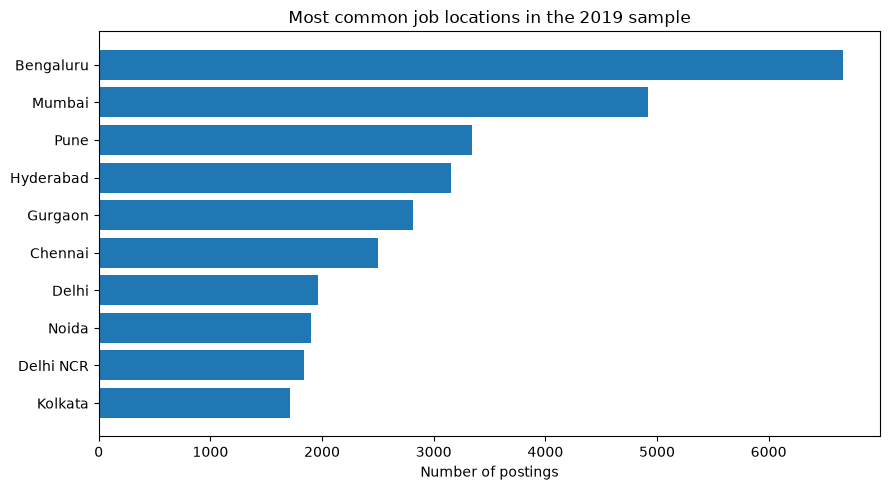

In [23]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

connection = sqlite3.connect(project_root / "data" / "jobs.db")

jobs = pd.read_sql_query(
    'SELECT "Uniq Id", "Location" FROM job_postings_clean',
    connection,
)

connection.close()

# Drop postings without a location, then split multi-location entries
location_rows = jobs.dropna(subset=["Location"]).copy()
location_rows["location_label"] = location_rows["Location"].str.split(",")
location_rows = location_rows.explode("location_label")

# Remove extra spaces and repeated locations within one posting
location_rows["location_label"] = location_rows["location_label"].str.strip()
location_rows = location_rows[
    location_rows["location_label"].ne("")
]
location_rows = location_rows.drop_duplicates(
    subset=["Uniq Id", "location_label"]
)

# Haryana is a state qualifier, not a city label in this analysis
location_rows = location_rows[
    location_rows["location_label"].str.casefold() != "haryana"
]

# Count distinct postings per location label
city_counts = (
    location_rows.groupby("location_label")["Uniq Id"]
    .nunique()
    .sort_values(ascending=False)
)

display(city_counts.head(15).rename("posting_count").to_frame())

# Plot the ten most common location labels
top_cities = city_counts.head(10).sort_values()

plt.figure(figsize=(9, 5))
plt.barh(top_cities.index, top_cities.values)
plt.xlabel("Number of postings")
plt.title("Most common job locations in the 2019 sample")
plt.tight_layout()
plt.show()

In [24]:
import sqlite3
import pandas as pd

connection = sqlite3.connect(project_root / "data" / "jobs.db")

technical_skills = pd.read_sql_query(
    "SELECT job_id, skill FROM job_technical_skills",
    connection,
)

connection.close()

# Connect each posting-location pair to its recognized technical skills
city_skill_rows = location_rows.merge(
    technical_skills,
    left_on="Uniq Id",
    right_on="job_id",
    how="inner",
)

# Count each posting once per location and skill
city_skill_rows = city_skill_rows.drop_duplicates(
    subset=["Uniq Id", "location_label", "skill"]
)

# Show the five most common recognized skills for each top location
for location in city_counts.head(10).index:
    top_skills = (
        city_skill_rows[city_skill_rows["location_label"] == location]
        .groupby("skill")["Uniq Id"]
        .nunique()
        .sort_values(ascending=False)
        .head(5)
        .rename("posting_count")
        .to_frame()
    )

    print(f"\nTop recognized technical skills for: {location}")
    display(top_skills)


Top recognized technical skills for: Bengaluru


,posting_count
skill,
sql,625
javascript,591
java,558
python,457
html,382



Top recognized technical skills for: Mumbai


,posting_count
skill,
sql,280
javascript,259
html,197
java,182
excel,136



Top recognized technical skills for: Pune


,posting_count
skill,
javascript,319
sql,314
java,229
html,201
python,142


... (10 outputs left out)


Top recognized technical skills for: Delhi NCR


,posting_count
skill,
javascript,68
java,67
sql,56
css,31
excel,30



Top recognized technical skills for: Kolkata


,posting_count
skill,
javascript,68
data analysis,61
html,57
sql,45
mysql,38


In [25]:
import sqlite3
import pandas as pd

connection = sqlite3.connect(project_root / "data" / "jobs.db")

experience_formats = pd.read_sql_query(
    '''
    SELECT
        "Job Experience Required" AS experience,
        COUNT(*) AS posting_count
    FROM job_postings_clean
    GROUP BY "Job Experience Required"
    ORDER BY posting_count DESC
    LIMIT 25
    ''',
    connection,
)

connection.close()
display(experience_formats)


,experience,posting_count
0,2 - 5 yrs,2002
1,2 - 7 yrs,1659
2,5 - 10 yrs,1510
3,3 - 8 yrs,1366
4,1 - 3 yrs,1189
5,3 - 5 yrs,1063
6,1 - 6 yrs,1032
7,1 - 5 yrs,977
8,0 - 5 yrs,933
9,0 - 1 yrs,855


Postings with both salary and experience parsed: 8393


,experience_band,posting_count,median_salary_lpa,mean_salary_lpa
0,Up to 2,1997,2.250,51.566540
1,Over 2 to 5,3567,3.375,57.839660
2,Over 5 to 10,2152,7.500,8.067056
3,Over 10,677,14.500,16.770508


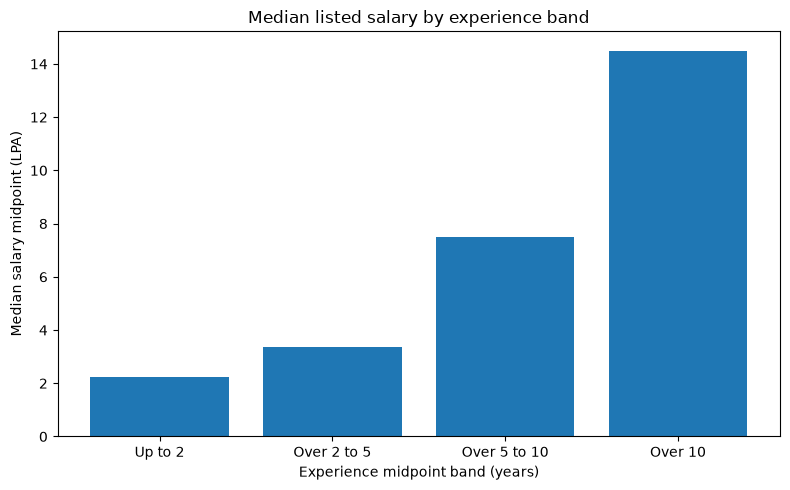

In [26]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

from src.experience_parser import parse_experience_years

connection = sqlite3.connect(project_root / "data" / "jobs.db")

salary_experience = pd.read_sql_query(
    '''
    SELECT
        "Uniq Id",
        "Job Experience Required",
        salary_mid_lpa
    FROM job_postings_clean
    ''',
    connection,
)

connection.close()

# Convert each experience range to its midpoint in years
salary_experience["experience_mid_years"] = (
    salary_experience["Job Experience Required"].apply(
        lambda value: (
            parse_experience_years(value)[2]
            if parse_experience_years(value) is not None
            else None
        )
    )
)

# Keep rows with both a parsed salary and parsed experience
analysis_data = salary_experience.dropna(
    subset=["salary_mid_lpa", "experience_mid_years"]
).copy()

# Put each experience midpoint into a readable band
analysis_data["experience_band"] = pd.cut(
    analysis_data["experience_mid_years"],
    bins=[-0.01, 2, 5, 10, float("inf")],
    labels=["Up to 2", "Over 2 to 5", "Over 5 to 10", "Over 10"],
    include_lowest=True,
)

# Summarize salary by experience band
salary_by_experience = (
    analysis_data.groupby("experience_band", observed=True)
    .agg(
        posting_count=("Uniq Id", "nunique"),
        median_salary_lpa=("salary_mid_lpa", "median"),
        mean_salary_lpa=("salary_mid_lpa", "mean"),
    )
    .reset_index()
)

print(f"Postings with both salary and experience parsed: {len(analysis_data)}")
display(salary_by_experience)

# Plot median salary because it is less affected by unusually high values
plt.figure(figsize=(8, 5))
plt.bar(
    salary_by_experience["experience_band"].astype(str),
    salary_by_experience["median_salary_lpa"],
)
plt.xlabel("Experience midpoint band (years)")
plt.ylabel("Median salary midpoint (LPA)")
plt.title("Median listed salary by experience band")
plt.tight_layout()
plt.show()

In [27]:
print(
    "Postings with both salary and experience parsed:",
    len(analysis_data),
)
display(salary_by_experience)

Postings with both salary and experience parsed: 8393


,experience_band,posting_count,median_salary_lpa,mean_salary_lpa
0,Up to 2,1997,2.250,51.566540
1,Over 2 to 5,3567,3.375,57.839660
2,Over 5 to 10,2152,7.500,8.067056
3,Over 10,677,14.500,16.770508


In [28]:
import sqlite3
import pandas as pd

from src.experience_parser import parse_experience_years

connection = sqlite3.connect(project_root / "data" / "jobs.db")

salary_audit = pd.read_sql_query(
    '''
    SELECT
        "Uniq Id",
        "Job Title",
        "Job Salary",
        "Job Experience Required",
        salary_mid_lpa
    FROM job_postings_clean
    WHERE salary_mid_lpa IS NOT NULL
    ''',
    connection,
)

connection.close()


def experience_midpoint(value):
    parsed = parse_experience_years(value)
    return parsed[2] if parsed is not None else None


salary_audit["experience_mid_years"] = (
    salary_audit["Job Experience Required"].apply(experience_midpoint)
)

salary_audit["experience_band"] = pd.cut(
    salary_audit["experience_mid_years"],
    bins=[-0.01, 2, 5, 10, float("inf")],
    labels=["Up to 2", "Over 2 to 5", "Over 5 to 10", "Over 10"],
    include_lowest=True,
)

for band in ["Up to 2", "Over 2 to 5"]:
    print(f"\nHighest parsed salaries for experience band: {band}")

    display(
        salary_audit[salary_audit["experience_band"] == band]
        .sort_values("salary_mid_lpa", ascending=False)
        .head(10)
    )


Highest parsed salaries for experience band: Up to 2


,Uniq Id,Job Title,Job Salary,Job Experience Required,salary_mid_lpa,experience_mid_years,experience_band
2907,52b60ee6851f3c8eca5fd03fc4c9269b,CPC Certification For Medical Coding Fresher -...,"Chennai, Salem, Vellore, Tirunelveli. Whatsapp...",0 - 0 yrs,98145.2246,0.0,Up to 2
1964,de712d4076a6a6b3c253f97cad87c81d,Njs2619a- Interventional Cardiologist(dm/dnb)-...,"35,00,000 - 60,00,000 PA.",0 - 3 yrs,47.5000,1.5,Up to 2
8291,c675b52e55b68f28ca0e823632e543a6,Associate Consultant-neurosurgery,"16,00,000 - 25,00,000 PA.",0 - 1 yrs,20.5000,0.5,Up to 2
7445,7a36d59cc994dbe84cb02d6991cef9ca,Hiring Fresher Sonologist _private Hospital_ut...,"18,00,000 - 20,00,000 PA.",0 - 4 yrs,19.0000,2.0,Up to 2
2456,3cc227d07cd3db97419b724958321024,"Marketing Technologist, Leading FMCG Company, ...","INR 18,00,000 - 20,00,000 PA.",1 - 3 Years,19.0000,2.0,Up to 2
5522,6d37bdc2e6e728058c33ebb9e8b57d6b,Manager Business Excellence IIM / MBA TIER 1 B...,"15,00,000 - 20,00,000 PA.",1 - 3 yrs,17.5000,2.0,Up to 2
658,a5258f4bc180dec73affd6f753b0f865,Surgeon Doctor,"12,00,000 - 22,00,000 PA.",1 - 3 yrs,17.0000,2.0,Up to 2
2103,b267190065abbc85b460a0c1a262dc21,Process Technology Engineer,"12,00,000 - 15,00,000 PA.",0 - 2 yrs,13.5000,1.0,Up to 2
4318,3f57c622f226b8ede900e7334d546388,Sonologist,"10,00,000 - 16,00,000 PA.",0 - 4 yrs,13.0000,2.0,Up to 2
7431,ea26ad78abddf3968280d3b5473db574,Software Developer,"8,00,000 - 18,00,000 PA.",1 - 3 yrs,13.0000,2.0,Up to 2



Highest parsed salaries for experience band: Over 2 to 5


,Uniq Id,Job Title,Job Salary,Job Experience Required,salary_mid_lpa,experience_mid_years,experience_band
8279,1e6157c2f0d791936343cbfac7f12bc6,Hiring Technical Sales Executive / Ppc/popup C...,Incentives +cab+meal-8448100705,1 - 5 yrs,84481.00705,3.0,Over 2 to 5
3175,ae36abcd53879d1a9606cd0d0655208d,Technical Sales Executive || Need ppc / Popup ...,Incentives +cab+meal-8448100705,1 - 5 yrs,84481.00705,3.0,Over 2 to 5
1285,28af76da8f744cc112c8b5b905592e57,Asstt. Professor - Neural Engineering (SA Facu...,INR Pay Band 3 (Rs.15600-39100) with AGP of Rs...,3 - 5 yrs,7801.50000,4.0,Over 2 to 5
6333,afc5d6c288311ceec753097dc9416cab,Asstt. Professor - Partial Differential Equati...,INR Pay Band 3 (Rs.15600-39100) with AGP of Rs...,3 - 5 yrs,7801.50000,4.0,Over 2 to 5
406,ce621be85ea9e6b7ab9809d110543f7d,Asstt. Professor - Computer Science & Engineer...,INR Pay Band 3 (Rs.15600-39100) with AGP of Rs...,3 - 5 yrs,7801.50000,4.0,Over 2 to 5
5878,1f9d4e048e5ba231231f55e0cc3b225b,Urgent Requirement for JavaScript Developer at...,"1,00,00,000 PA.",2 - 7 yrs,100.00000,4.5,Over 2 to 5
6982,685e74a0d5884afb1f17df4cedea094c,"Category Business Head || IIT, NIT, BITS || ex...","30,00,000 - 40,00,000 PA.",3 - 7 yrs,35.00000,5.0,Over 2 to 5
5080,29c2565dad2ce430b786e0af099fcae0,Business Development Manager,"30,00,000 - 37,50,000 PA.",2 - 5 yrs,33.75000,3.5,Over 2 to 5
1518,e1614f30a4b3f12d67ca4b81087adf59,Consultant General Surgeon For NCR and Haryana,"27,50,000 - 30,00,000 PA.",3 - 5 yrs,28.75000,4.0,Over 2 to 5
4711,ce46947a03336651b448415d77ed324d,Urgent Vacancy For Radiologist in Diagnostic C...,"25,00,000 - 30,00,000 PA.",0 - 5 yrs,27.50000,2.5,Over 2 to 5


Postings with salary and experience parsed: 7729


,experience_band,posting_count,median_salary_lpa,mean_salary_lpa
0,Up to 2,1908,2.25,2.533592
1,Over 2 to 5,3324,3.50,4.190629
2,Over 5 to 10,1919,8.00,9.037993
3,Over 10,578,16.50,19.607852


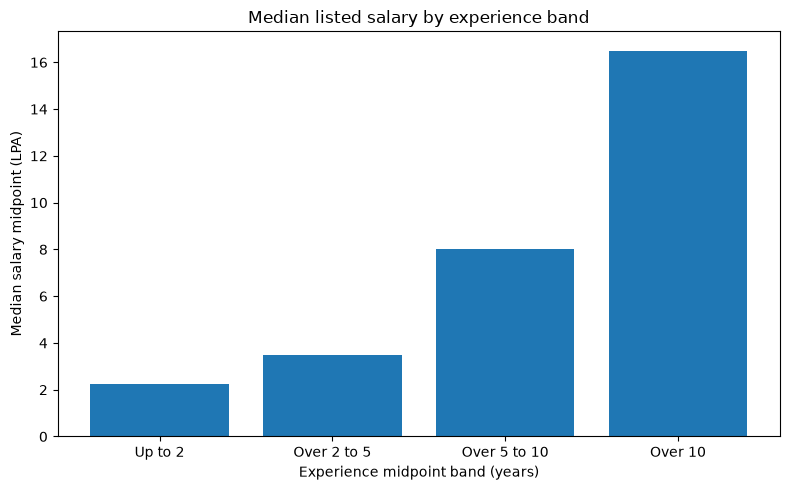

In [29]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

from src.experience_parser import parse_experience_years

connection = sqlite3.connect(project_root / "data" / "jobs.db")

salary_experience = pd.read_sql_query(
    '''
    SELECT
        "Uniq Id",
        "Job Experience Required",
        salary_mid_lpa
    FROM job_postings_clean
    ''',
    connection,
)

connection.close()


def experience_midpoint(value):
    parsed = parse_experience_years(value)
    return parsed[2] if parsed is not None else None


salary_experience["experience_mid_years"] = (
    salary_experience["Job Experience Required"].apply(experience_midpoint)
)

analysis_data = salary_experience.dropna(
    subset=["salary_mid_lpa", "experience_mid_years"]
).copy()

analysis_data["experience_band"] = pd.cut(
    analysis_data["experience_mid_years"],
    bins=[-0.01, 2, 5, 10, float("inf")],
    labels=["Up to 2", "Over 2 to 5", "Over 5 to 10", "Over 10"],
    include_lowest=True,
)

salary_by_experience = (
    analysis_data.groupby("experience_band", observed=True)
    .agg(
        posting_count=("Uniq Id", "nunique"),
        median_salary_lpa=("salary_mid_lpa", "median"),
        mean_salary_lpa=("salary_mid_lpa", "mean"),
    )
    .reset_index()
)

print(f"Postings with salary and experience parsed: {len(analysis_data)}")
display(salary_by_experience)

plt.figure(figsize=(8, 5))
plt.bar(
    salary_by_experience["experience_band"].astype(str),
    salary_by_experience["median_salary_lpa"],
)
plt.xlabel("Experience midpoint band (years)")
plt.ylabel("Median salary midpoint (LPA)")
plt.title("Median listed salary by experience band")
plt.tight_layout()
plt.show()

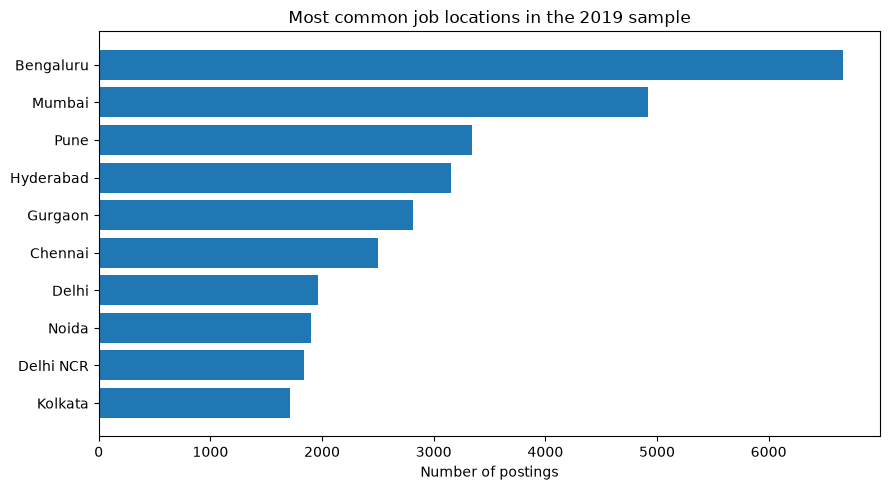

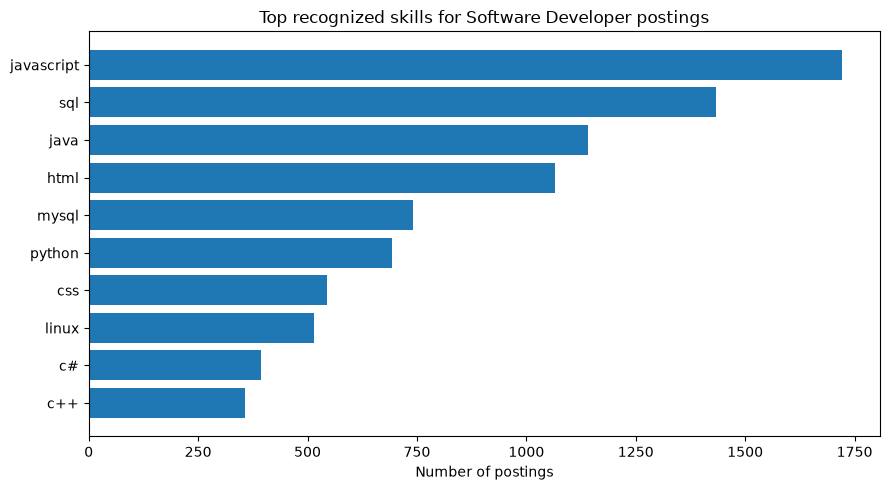

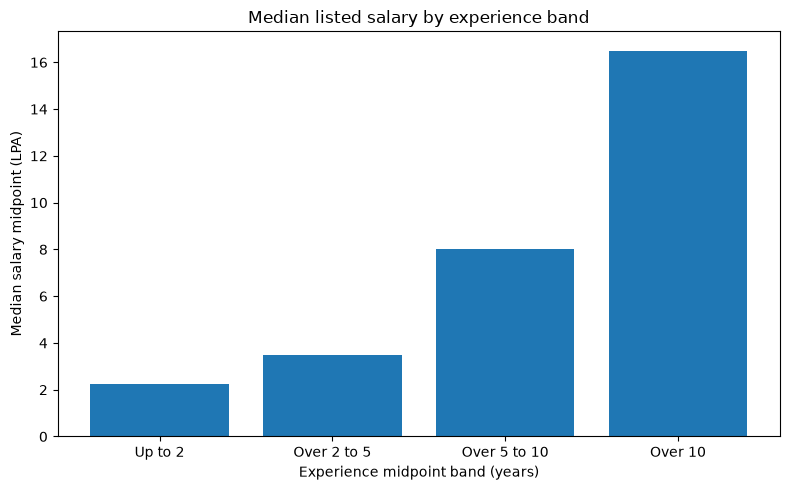

Saved charts to: c:\Users\Ramesh\OneDrive\Pictures\Desktop\Documents\india-job-market-rag-assistant\reports\figures


In [30]:
import matplotlib.pyplot as plt

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Chart 1: most common location labels
top_locations = city_counts.head(10).sort_values()

plt.figure(figsize=(9, 5))
plt.barh(top_locations.index, top_locations.values)
plt.xlabel("Number of postings")
plt.title("Most common job locations in the 2019 sample")
plt.tight_layout()
plt.savefig(
    figures_dir / "top_job_locations.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()
plt.close()

# Chart 2: most common recognized technical skills for Software Developers
developer_skills = (
    role_skills[role_skills["role"] == "Software Developer"]
    .head(10)
    .sort_values("posting_count")
)

plt.figure(figsize=(9, 5))
plt.barh(developer_skills["skill"], developer_skills["posting_count"])
plt.xlabel("Number of postings")
plt.title("Top recognized skills for Software Developer postings")
plt.tight_layout()
plt.savefig(
    figures_dir / "software_developer_skills.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()
plt.close()

# Chart 3: median salary by experience band
plt.figure(figsize=(8, 5))
plt.bar(
    salary_by_experience["experience_band"].astype(str),
    salary_by_experience["median_salary_lpa"],
)
plt.xlabel("Experience midpoint band (years)")
plt.ylabel("Median salary midpoint (LPA)")
plt.title("Median listed salary by experience band")
plt.tight_layout()
plt.savefig(
    figures_dir / "salary_by_experience.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()
plt.close()

print(f"Saved charts to: {figures_dir}")